In [1]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
import matplotlib.pyplot as plt
from scipy.stats import beta
from tqdm import tqdm

# 固定随机种子，保证可复现
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.cuda.manual_seed_all(SEED)

# 设备配置
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Current device: {device}")

# 全局超参数
IMG_SIZE = 100
BATCH_SIZE = 128
MOMENTUM = 0.9
PADDING = 12
FLIP_PROB = 0.5


Current device: cuda


In [2]:
class DogBreedDataset(Dataset):
    def __init__(self, img_dir, labels_df, transform=None, breed_to_idx=None):
        self.img_dir = img_dir
        self.labels_df = labels_df.reset_index(drop=True)
        self.transform = transform
        # 类别映射：优先使用传入的统一映射（以训练集为准）
        if breed_to_idx is not None:
            self.breed_to_idx = breed_to_idx
        else:
            self.breed_to_idx = {
                breed: idx
                for idx, breed in enumerate(sorted(labels_df["breed"].unique()))
            }
        self.num_classes = len(self.breed_to_idx)

    def __len__(self):
        return len(self.labels_df)

    def __getitem__(self, idx):
        img_id = self.labels_df.iloc[idx]["id"]
        img_path = os.path.join(self.img_dir, f"{img_id}.jpg")
        image = Image.open(img_path).convert("RGB")
        label = self.breed_to_idx[self.labels_df.iloc[idx]["breed"]]

        if self.transform:
            image = self.transform(image)
        return image, label


In [3]:
# 读取独立的标签文件
train_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/data/train_labels.csv")
val_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/data/val_labels.csv")
test_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/data/test_labels.csv")

print(f"Train samples: {len(train_df)}")
print(f"Val samples: {len(val_df)}")
print(f"Test samples: {len(test_df)}")


Train samples: 7155
Val samples: 1533
Test samples: 1534


In [4]:
def compute_train_stats(img_dir, train_df):
    """仅用训练集计算RGB通道均值和标准差，用于归一化"""
    transform = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor()
    ])
    dataset = DogBreedDataset(img_dir, train_df, transform=transform)
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

    channel_sum = torch.zeros(3)
    channel_sq_sum = torch.zeros(3)
    total_pixels = 0

    for imgs, _ in tqdm(loader, desc="Computing training set stats"):
        batch_pixels = imgs.size(0) * imgs.size(2) * imgs.size(3)
        channel_sum += imgs.sum(dim=[0, 2, 3])
        channel_sq_sum += (imgs ** 2).sum(dim=[0, 2, 3])
        total_pixels += batch_pixels

    mean = channel_sum / total_pixels
    std = torch.sqrt(channel_sq_sum / total_pixels - mean ** 2)
    return mean.numpy(), std.numpy()

# 计算并打印训练集统计量（写入报告）
train_mean, train_std = compute_train_stats("/content/drive/MyDrive/Colab Notebooks/data/train/images", train_df)
print(f"\nTraining set mean (R,G,B): {train_mean.round(4)}")
print(f"Training set std (R,G,B): {train_std.round(4)}")


Computing training set stats: 100%|██████████| 56/56 [1:02:46<00:00, 67.25s/it]


Training set mean (R,G,B): [0.4772 0.4528 0.3928]
Training set std (R,G,B): [0.2534 0.248  0.2523]


In [5]:
# 训练集：数据增强 + 归一化
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.Pad(PADDING, fill=0, padding_mode="constant"),
    transforms.RandomCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(p=FLIP_PROB),
    transforms.ToTensor(),
    transforms.Normalize(mean=train_mean, std=train_std)
])

# 验证/测试集：无增强，仅resize+归一化
val_test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=train_mean, std=train_std)
])

# 创建三个数据集，复用训练集的类别映射
train_dataset = DogBreedDataset("/content/drive/MyDrive/Colab Notebooks/data/train/images", train_df, transform=train_transform)
breed_to_idx = train_dataset.breed_to_idx  # 统一类别映射
num_classes = train_dataset.num_classes

val_dataset = DogBreedDataset(
    "/content/drive/MyDrive/Colab Notebooks/data/val/images", val_df,
    transform=val_test_transform,
    breed_to_idx=breed_to_idx
)
test_dataset = DogBreedDataset(
    "/content/drive/MyDrive/Colab Notebooks/data/test/images", test_df,
    transform=val_test_transform,
    breed_to_idx=breed_to_idx
)

# 创建数据加载器
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


In [6]:
def get_model():
    """EfficientNetV2-S，从头训练（无预训练权重）"""
    return models.efficientnet_v2_s(weights=None, num_classes=num_classes)

def train_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    for imgs, labels in tqdm(loader, desc="Training"):
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * imgs.size(0)
        _, pred = outputs.max(1)
        total += labels.size(0)
        correct += pred.eq(labels).sum().item()
    return total_loss / total, correct / total

def val_epoch(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for imgs, labels in tqdm(loader, desc="Evaluating"):
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * imgs.size(0)
            _, pred = outputs.max(1)
            total += labels.size(0)
            correct += pred.eq(labels).sum().item()
    return total_loss / total, correct / total

def run_training(model, num_epochs, lr, weight_decay, use_cosine=False):
    """通用训练流程，支持余弦退火调度"""
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(
        model.parameters(),
        lr=lr,
        momentum=MOMENTUM,
        weight_decay=weight_decay
    )
    scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=num_epochs, eta_min=0
    ) if use_cosine else None

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for epoch in range(num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")
        train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = val_epoch(model, val_loader, criterion)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"Train Loss: {train_loss:.4f} | Accuracy: {train_acc:.4f}")
        print(f"Val   Loss: {val_loss:.4f} | Accuracy: {val_acc:.4f}")

        if scheduler:
            scheduler.step()
            print(f"Current LR: {scheduler.get_last_lr()[0]:.6f}")
    return history

def plot_curves(history, title, save_name):
    """绘制训练/验证Loss和Accuracy曲线"""
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    ax1.plot(epochs, history["train_loss"], "b-", label="Train Loss")
    ax1.plot(epochs, history["val_loss"], "r-", label="Val Loss")
    ax1.set_title("Loss Curve")
    ax1.set_xlabel("Number of Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend()

    ax2.plot(epochs, history["train_acc"], "b-", label="Train Accuracy")
    ax2.plot(epochs, history["val_acc"], "r-", label="Val Accuracy")
    ax2.set_title("Accuracy Curve")
    ax2.set_xlabel("Number of Epochs")
    ax2.set_ylabel("Accuracy")
    ax2.legend()

    plt.suptitle(title)
    plt.tight_layout()
    plt.savefig(save_name, dpi=300, bbox_inches="tight")
    files.download(save_name)
    plt.show()
    plt.close()


#### 3. Learning Rate


Experiment: Learning rate = 0.5

Epoch 1/15


Evaluating: 100%|██████████| 12/12 [13:22<00:00, 66.86s/it]


Train Loss: 5.6003 | Accuracy: 0.0091
Val   Loss: 6.0876 | Accuracy: 0.0085

Epoch 2/15


Evaluating: 100%|██████████| 12/12 [00:09<00:00,  1.32it/s]


Train Loss: 4.8537 | Accuracy: 0.0073
Val   Loss: 4.8114 | Accuracy: 0.0104

Epoch 3/15


...

Train Loss: 4.6579 | Accuracy: 0.0161
Val   Loss: 4.6247 | Accuracy: 0.0163

Epoch 14/15


Evaluating: 100%|██████████| 12/12 [00:09<00:00,  1.32it/s]


Train Loss: 4.6345 | Accuracy: 0.0193
Val   Loss: 4.6738 | Accuracy: 0.0209

Epoch 15/15


Evaluating: 100%|██████████| 12/12 [00:09<00:00,  1.32it/s]


Train Loss: 4.6119 | Accuracy: 0.0196
Val   Loss: 4.6459 | Accuracy: 0.0189


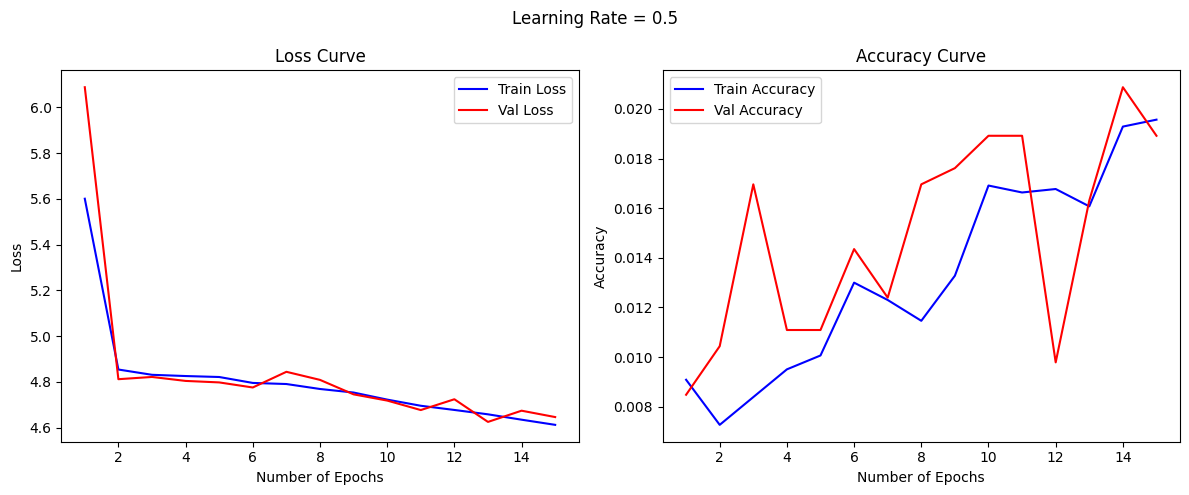


Experiment: Learning rate = 0.05

Epoch 1/15


Evaluating: 100%|██████████| 12/12 [00:09<00:00,  1.33it/s]


Train Loss: 5.3026 | Accuracy: 0.0067
Val   Loss: 45.9355 | Accuracy: 0.0104

Epoch 2/15


Evaluating: 100%|██████████| 12/12 [00:08<00:00,  1.34it/s]


Train Loss: 5.0173 | Accuracy: 0.0101
Val   Loss: 4.9256 | Accuracy: 0.0072

Epoch 3/15


...

Train Loss: 4.4507 | Accuracy: 0.0386
Val   Loss: 4.4805 | Accuracy: 0.0450

Epoch 14/15


Evaluating: 100%|██████████| 12/12 [00:09<00:00,  1.32it/s]


Train Loss: 4.4285 | Accuracy: 0.0397
Val   Loss: 4.4832 | Accuracy: 0.0294

Epoch 15/15


Evaluating: 100%|██████████| 12/12 [00:08<00:00,  1.35it/s]


Train Loss: 4.3874 | Accuracy: 0.0408
Val   Loss: 4.4467 | Accuracy: 0.0359


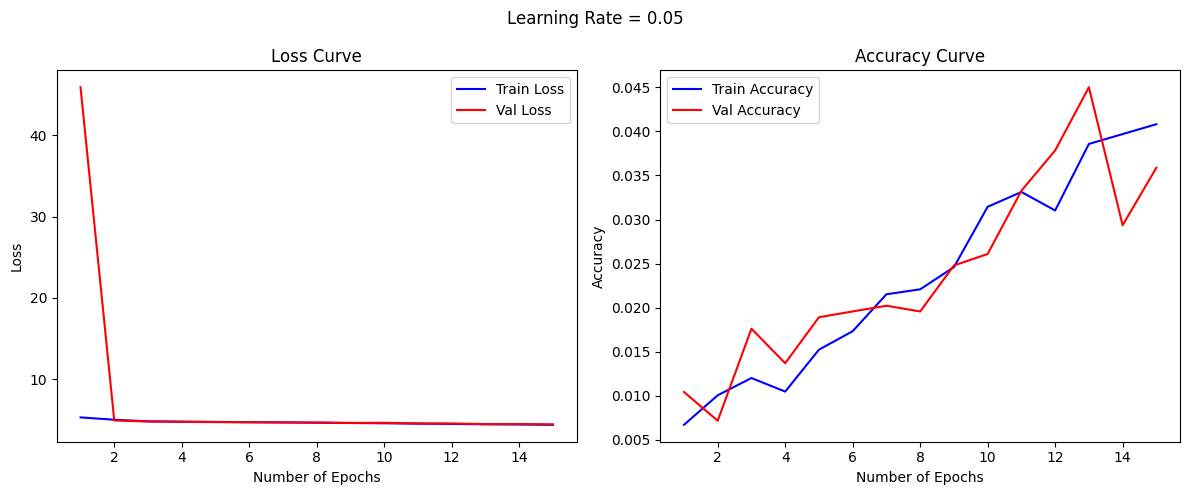


Experiment: Learning rate = 0.001

Epoch 1/15


Evaluating: 100%|██████████| 12/12 [00:08<00:00,  1.36it/s]


Train Loss: 4.9694 | Accuracy: 0.0092
Val   Loss: 4.7902 | Accuracy: 0.0117

Epoch 2/15


Evaluating: 100%|██████████| 12/12 [00:09<00:00,  1.33it/s]


Train Loss: 4.9385 | Accuracy: 0.0088
Val   Loss: 4.8615 | Accuracy: 0.0098

Epoch 3/15


...

Train Loss: 4.8463 | Accuracy: 0.0138
Val   Loss: 4.9021 | Accuracy: 0.0111

Epoch 14/15


Evaluating: 100%|██████████| 12/12 [00:08<00:00,  1.38it/s]


Train Loss: 4.8544 | Accuracy: 0.0106
Val   Loss: 4.8958 | Accuracy: 0.0098

Epoch 15/15


Evaluating: 100%|██████████| 12/12 [00:09<00:00,  1.33it/s]


Train Loss: 4.8458 | Accuracy: 0.0112
Val   Loss: 4.8281 | Accuracy: 0.0085


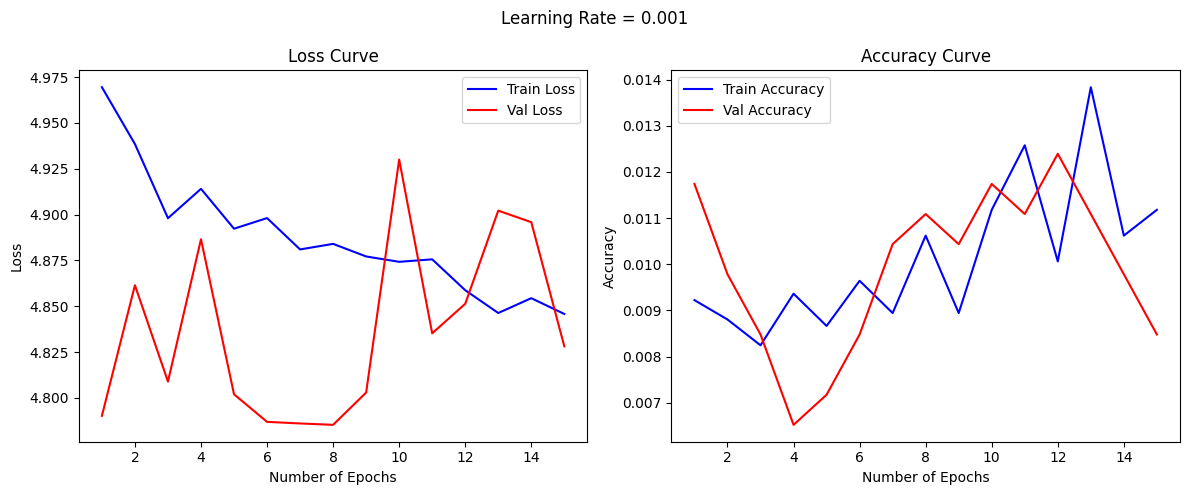


Final Results (15 epochs):
LR       Train Loss   Train Accuracy Val Loss     Val Accuracy
0.5      4.6119       0.0196       4.6459       0.0189      
0.05     4.3874       0.0408       4.4467       0.0359      
0.001    4.8458       0.0112       4.8281       0.0085      

Best initial learning rate: 0.05


In [7]:
lr_candidates = [0.5, 0.05, 0.001]
lr_histories = {}

for lr in lr_candidates:
    print(f"\n{'='*50}")
    print(f"Experiment: Learning rate = {lr}")
    print('='*50)
    model = get_model().to(device)
    history = run_training(
        model, num_epochs=15, lr=lr, weight_decay=0, use_cosine=False
    )
    lr_histories[lr] = history
    plot_curves(history, f"Learning Rate = {lr}", f"lr_{lr}.png")

# 输出最终结果
print("\nFinal Results (15 epochs):")
print(f"{'LR':<8} {'Train Loss':<12} {'Train Accuracy':<12} {'Val Loss':<12} {'Val Accuracy':<12}")
for lr, hist in lr_histories.items():
    print(f"{lr:<8} {hist['train_loss'][-1]:<12.4f} {hist['train_acc'][-1]:<12.4f} {hist['val_loss'][-1]:<12.4f} {hist['val_acc'][-1]:<12.4f}")

# 选出验证集准确率最优的初始学习率
best_lr = max(lr_histories.keys(), key=lambda x: lr_histories[x]["val_acc"][-1])
print(f"\nBest initial learning rate: {best_lr}")


#### 4. Learning Rate Schedule

In [ ]:
# Fixed learning rate 300 epoch
print(f"\n{'='*50}")
print("Experiment: Constant Learning Rate (300 epochs)")
print('='*50)
model_const = get_model().to(device)
hist_const = run_training(
    model_const, num_epochs=300, lr=best_lr, weight_decay=0, use_cosine=False
)
plot_curves(hist_const, "Constant Learning Rate", "constant_lr.png")

# Cosine Annealing 300 epoch
print(f"\n{'='*50}")
print("Experiment: Cosine Annealing LR (300 epochs)")
print('='*50)
model_cos = get_model().to(device)
hist_cos = run_training(
    model_cos, num_epochs=300, lr=best_lr, weight_decay=0, use_cosine=True
)
plot_curves(hist_cos, "Cosine Annealing Learning Rate", "cosine_lr.png")



Experiment: Constant Learning Rate (300 epochs)

Epoch 1/300


Evaluating: 100%|██████████| 12/12 [00:08<00:00,  1.34it/s]


Train Loss: 5.2576 | Accuracy: 0.0098
Val   Loss: 4.7809 | Accuracy: 0.0124

Epoch 2/300


Evaluating: 100%|██████████| 12/12 [00:08<00:00,  1.34it/s]


Train Loss: 4.9812 | Accuracy: 0.0115
Val   Loss: 5.5241 | Accuracy: 0.0085

Epoch 3/300


...

Evaluating: 100%|██████████| 12/12 [00:09<00:00,  1.28it/s]


Train Loss: 0.0479 | Accuracy: 0.9849
Val   Loss: 8.9115 | Accuracy: 0.1409

Epoch 143/300


Evaluating: 100%|██████████| 12/12 [00:09<00:00,  1.28it/s]


Train Loss: 0.0461 | Accuracy: 0.9867
Val   Loss: 9.0445 | Accuracy: 0.1409

Epoch 144/300


Training:  41%|████      | 23/56 [00:25<00:36,  1.11s/it]

#### 5. Weight Decay

In [ ]:
wd_candidates = [5e-4, 1e-4]
wd_histories = {}

for wd in wd_candidates:
    print(f"\n{'='*50}")
    print(f"Experiment: Weight Decay = {wd}")
    print('='*50)
    model = get_model().to(device)
    history = run_training(
        model, num_epochs=300, lr=best_lr, weight_decay=wd, use_cosine=True
    )
    wd_histories[wd] = history
    plot_curves(history, f"Weight Decay = {wd}", f"wd_{wd}.png")

# 输出结果
print("\nFinal Results (300 epochs, cosine LR):")
print(f"{'Weight Decay':<15} {'Train Loss':<12} {'Train Accuracy':<12} {'Val Loss':<12} {'Val Accuracy':<12}")
for wd, hist in wd_histories.items():
    print(f"{wd:<15} {hist['train_loss'][-1]:<12.4f} {hist['train_acc'][-1]:<12.4f} {hist['val_loss'][-1]:<12.4f} {hist['val_acc'][-1]:<12.4f}")

# 选出最优权重衰减
best_wd = max(wd_histories.keys(), key=lambda x: wd_histories[x]["val_acc"][-1])
print(f"\nBest weight decay: {best_wd}")


#### 6. Data Augmentation: Mixup

In [ ]:
# 绘制 Beta(0.2, 0.2) 概率密度函数
alpha = 0.2
x = np.linspace(0, 1, 1000)
pdf = beta.pdf(x, alpha, alpha)
plt.figure(figsize=(6, 4))
plt.plot(x, pdf, "b-", linewidth=2)
plt.title(f"Beta Distribution PDF (α=β={alpha})")
plt.xlabel("λ")
plt.ylabel("Probability Density")
plt.grid(alpha=0.3)
plt.savefig("beta_pdf.png", dpi=300, bbox_inches="tight")
plt.close()

# Mixup 训练函数
def mixup_data(x, y, alpha):
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1.0
    idx = torch.randperm(x.size(0)).to(device)
    mixed_x = lam * x + (1 - lam) * x[idx]
    y_a, y_b = y, y[idx]
    return mixed_x, y_a, y_b, lam

def mixup_train_epoch(model, loader, criterion, optimizer, alpha):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    for imgs, labels in tqdm(loader, desc="Training (mixup)"):
        imgs, labels = imgs.to(device), labels.to(device)
        mixed_imgs, y_a, y_b, lam = mixup_data(imgs, labels, alpha)

        optimizer.zero_grad()
        outputs = model(mixed_imgs)
        loss = lam * criterion(outputs, y_a) + (1 - lam) * criterion(outputs, y_b)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * imgs.size(0)
        _, pred = outputs.max(1)
        total += labels.size(0)
        correct += lam * pred.eq(y_a).sum().item() + (1 - lam) * pred.eq(y_b).sum().item()
    return total_loss / total, correct / total

def run_mixup_training(model, num_epochs, lr, weight_decay, alpha):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(
        model.parameters(), lr=lr, momentum=MOMENTUM, weight_decay=weight_decay
    )
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=0)

    history = {"train_loss": [], "train_accuracy": [], "val_loss": [], "val_accuracy": []}
    for epoch in range(num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")
        train_loss, train_acc = mixup_train_epoch(
            model, train_loader, criterion, optimizer, alpha
        )
        val_loss, val_acc = val_epoch(model, val_loader, criterion)

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_acc)

        print(f"Train Loss: {train_loss:.4f} | Accuracy: {train_acc:.4f}")
        print(f"Val Loss: {val_loss:.4f} | Accuracy: {val_acc:.4f}")
        scheduler.step()
    return history

# 运行mixup实验
print(f"\n{'='*50}")
print("Experiment: Mixup Augmentation (α=0.2)")
print('='*50)
model_mixup = get_model().to(device)
hist_mixup = run_mixup_training(
    model_mixup, num_epochs=300, lr=best_lr, weight_decay=best_wd, alpha=0.2
)
plot_curves(hist_mixup, "Mixup Augmentation (α=0.2)", "mixup.png")

# 最终测试集准确率
test_loss, test_acc = val_epoch(model_mixup, test_loader, nn.CrossEntropyLoss())
print(f"\nFinal Test Accuracy: {test_acc:.4f}")
print(f"Final Test Loss: {test_loss:.4f}")
